In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

ps2 = pd.read_csv('PS2.txt', sep='\t', header=None)
fs1 = pd.read_csv('FS1.txt', sep='\t', header=None)
profile = pd.read_csv('profile.txt', sep='\t', header=None,
                      names=['cooler','valve','pump_leak','accumulator','stable'])
print(ps2.describe(), fs1.describe(), profile.describe())

              0            1            2            3            4     \
count  2205.000000  2205.000000  2205.000000  2205.000000  2205.000000   
mean    123.362422   123.364358   123.339202   122.831868   121.808503   
std       3.701729     3.694412     3.700527     3.819922     3.746546   
min     119.610000   119.630000   118.920000   118.650000   115.830000   
25%     121.630000   121.670000   121.660000   120.560000   118.830000   
50%     123.040000   123.040000   123.010000   122.620000   122.060000   
75%     125.100000   125.100000   125.090000   124.830000   124.480000   
max     165.480000   165.260000   165.530000   165.690000   160.570000   

              5            6            7            8            9     ...  \
count  2205.000000  2205.000000  2205.000000  2205.000000  2205.000000  ...   
mean    120.693455   104.294819    64.491438    35.220531    27.355589  ...   
std       3.541433     9.616892     8.636717     3.792106     3.286553  ...   
min      97.28900

In [ ]:
from scipy import stats

def extract(df, name, n_win=6):
    X = df.values
    f = {
        f'{name}_mean': X.mean(1),   f'{name}_std': X.std(1),
        f'{name}_min': X.min(1),     f'{name}_max': X.max(1),
        f'{name}_median': np.median(X, 1),
        f'{name}_q25': np.percentile(X, 25, 1), f'{name}_q75': np.percentile(X, 75, 1),
        f'{name}_ptp': np.ptp(X, 1), f'{name}_rms': np.sqrt((X**2).mean(1)),
        f'{name}_skew': stats.skew(X, 1), f'{name}_kurt': stats.kurtosis(X, 1),
        f'{name}_slope': np.polyfit(np.arange(X.shape[1]), X.T, 1)[0],
    }
    for i, w in enumerate(np.array_split(X, n_win, axis=1)):   # 6 fenêtres de 10 s
        f[f'{name}_w{i}_mean'] = w.mean(1)
        f[f'{name}_w{i}_std']  = w.std(1)
    return pd.DataFrame(f)

X = pd.concat([extract(ps2, 'PS2'), extract(fs1, 'FS1')], axis=1)
print(X.shape)   

(2205, 48)


In [4]:
y = (profile['valve'] == 100).astype(int)
X_train, X_test = X.iloc[:2000], X.iloc[2000:]
y_train, y_test = y.iloc[:2000], y.iloc[2000:]

In [5]:
display(profile.describe())
display(X_train.describe().T)
print(profile['valve'].value_counts())

,cooler,valve,pump_leak,accumulator,stable
count,2205.000000,2205.000000,2205.000000,2205.000000,2205.000000
mean,41.240816,90.693878,0.669388,107.199546,0.342857
std,42.383143,10.681802,0.817233,16.435848,0.474772
min,3.000000,73.000000,0.000000,90.000000,0.000000
25%,3.000000,80.000000,0.000000,90.000000,0.000000
50%,20.000000,100.000000,0.000000,100.000000,0.000000
75%,100.000000,100.000000,1.000000,130.000000,1.000000
max,100.000000,100.000000,2.000000,130.000000,1.000000


,count,mean,std,min,25%,50%,75%,max
PS2_mean,2000.0,1.093929e+02,5.234843,104.406307,106.834642,107.558399,109.380006,131.589089
PS2_std,2000.0,4.777506e+01,3.431611,45.203186,46.152657,46.639318,47.158258,59.548285
PS2_min,2000.0,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
PS2_max,2000.0,1.664498e+02,0.998311,155.040000,166.100000,166.570000,167.020000,167.740000
PS2_median,2000.0,1.285538e+02,3.619176,124.445000,127.025000,127.810000,129.875000,165.400000
PS2_q25,2000.0,1.179968e+02,1.715097,112.840000,116.480000,117.930000,120.060000,120.690000
PS2_q75,2000.0,1.327281e+02,12.019769,125.040000,127.645000,128.300000,130.470000,165.560000
PS2_ptp,2000.0,1.664498e+02,0.998311,155.040000,166.100000,166.570000,167.020000,167.740000
PS2_rms,2000.0,1.193750e+02,6.167282,114.004268,116.473327,117.186905,119.122161,144.200980
PS2_skew,2000.0,-1.770610e+00,0.146186,-1.842342,-1.835386,-1.830244,-1.793605,-1.317604


valve
100    1125
73      360
80      360
90      360
Name: count, dtype: int64


In [6]:
print(ps2.isna().sum().sum(), fs1.isna().sum().sum(), profile.isna().sum().sum())

0 0 0


In [7]:
Q1, Q3 = X_train.quantile(.25), X_train.quantile(.75)
IQR = Q3 - Q1
out = ((X_train < Q1 - 1.5*IQR) | (X_train > Q3 + 1.5*IQR)).sum().sort_values(ascending=False)
print(out.head(15))

FS1_w4_std     539
FS1_w1_std     419
FS1_w0_mean    308
FS1_w0_std     305
FS1_std        263
PS2_mean       240
PS2_q75        240
PS2_std        240
PS2_w3_mean    240
PS2_w3_std     240
PS2_w2_std     240
PS2_rms        240
PS2_slope      240
PS2_kurt       240
PS2_skew       240
dtype: int64


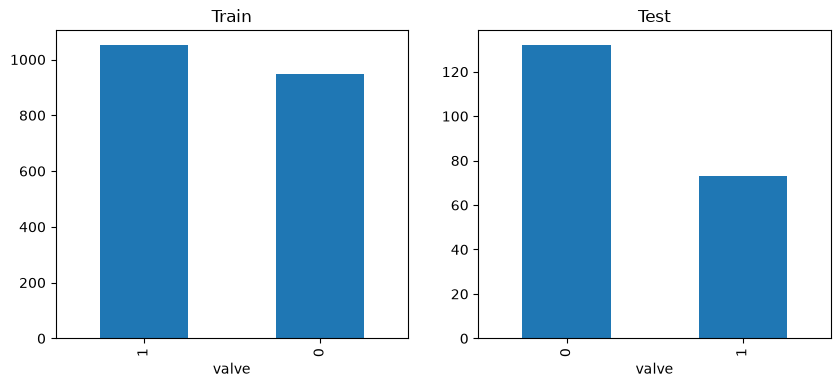

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot.bar(ax=ax[0], title='Train')
y_test.value_counts().plot.bar(ax=ax[1], title='Test')
plt.show()

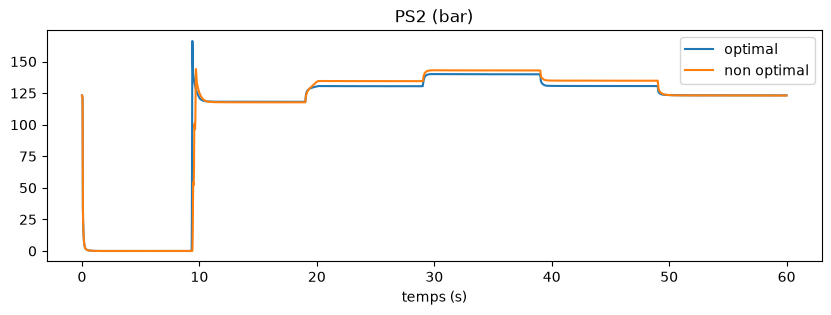

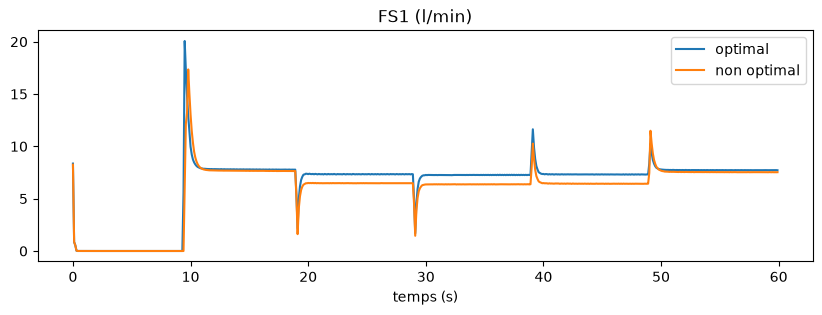

In [9]:
for sig, name, hz in [(ps2, 'PS2 (bar)', 100), (fs1, 'FS1 (l/min)', 10)]:
    t = np.arange(sig.shape[1]) / hz
    tr = sig.iloc[:2000]
    plt.figure(figsize=(10, 3))
    plt.plot(t, tr[y_train == 1].mean(), label='optimal')
    plt.plot(t, tr[y_train == 0].mean(), label='non optimal')
    plt.xlabel('temps (s)'); plt.title(name); plt.legend(); plt.show()

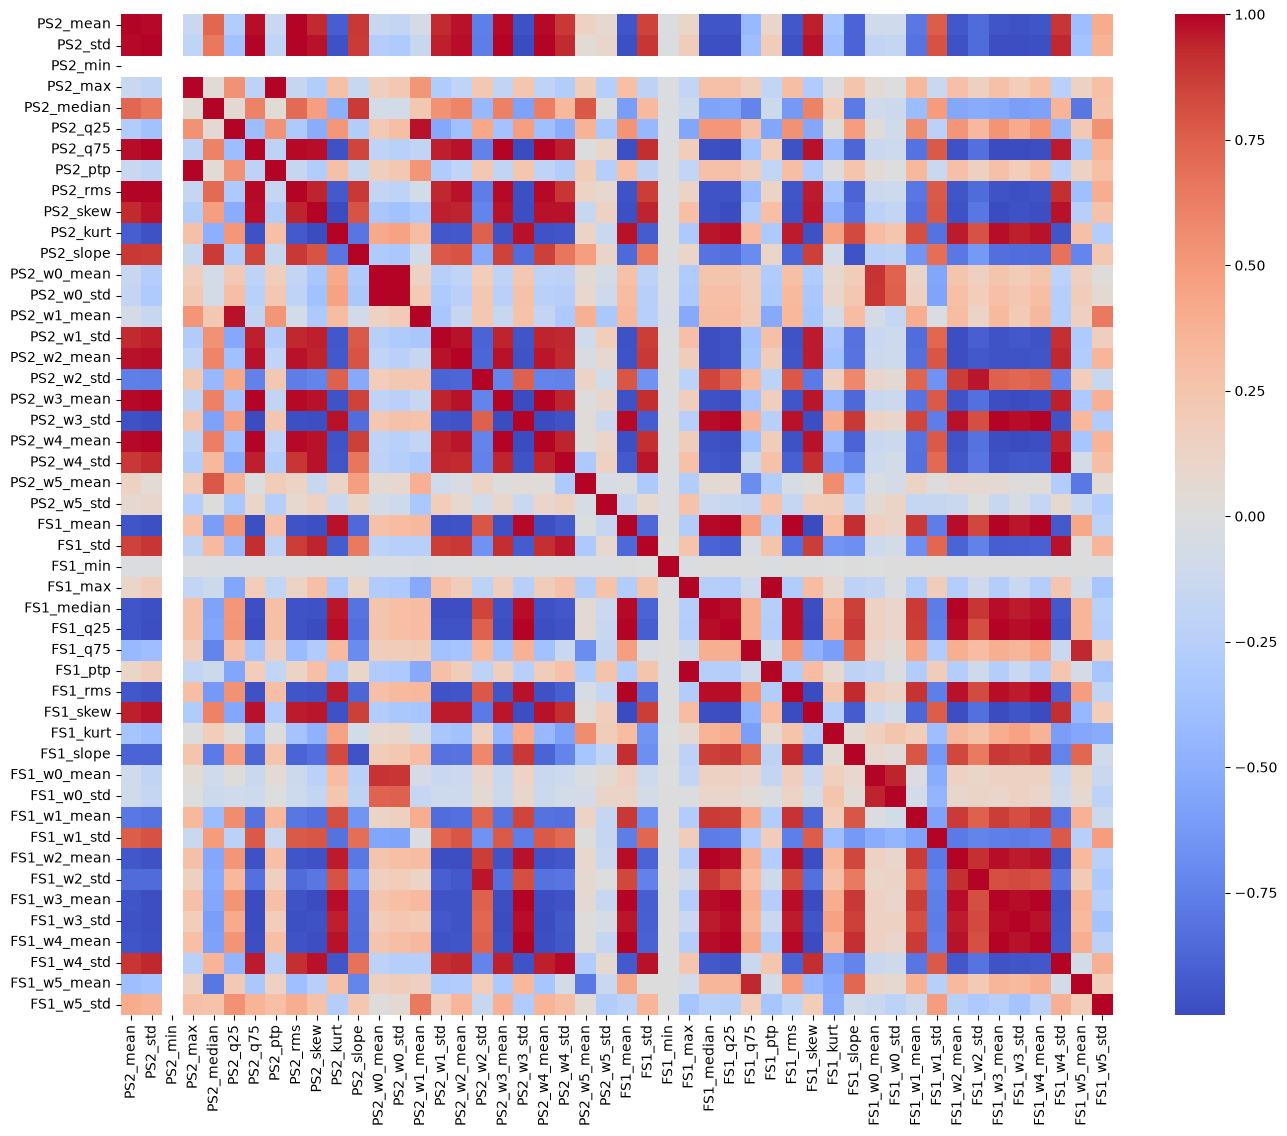

PS2_w0_mean    0.800229
PS2_w0_std     0.758500
FS1_w0_mean    0.589652
FS1_w1_std    -0.464220
FS1_w0_std     0.349644
PS2_kurt       0.342991
PS2_skew      -0.270045
FS1_skew      -0.258678
PS2_slope     -0.253538
FS1_rms        0.238537
FS1_mean       0.230846
PS2_std       -0.224583
FS1_w4_mean    0.210756
FS1_q25        0.209943
FS1_w3_mean    0.209065
dtype: float64


In [10]:
corr = X_train.corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.show()

print(X_train.corrwith(y_train).sort_values(key=abs, ascending=False).head(15))

In [11]:
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, f_classif
from sklearn.ensemble import RandomForestClassifier

# 1. Variance quasi nulle
vt = VarianceThreshold(1e-6).fit(X_train)
X_sel = X_train.loc[:, vt.get_support()]

# 2. Filtre de redondance : on retire une feature d'une paire si |r| > 0.95
c = X_sel.corr().abs()
upper = c.where(np.triu(np.ones(c.shape), 1).astype(bool))
drop = [col for col in upper if (upper[col] > 0.95).any()]
X_sel = X_sel.drop(columns=drop)
print(len(drop), 'retirées ->', X_sel.shape[1], 'restantes')

# 3. Scores univariés + importance d'une Random Forest
scores = pd.DataFrame({
    'ANOVA_F': f_classif(X_sel, y_train)[0],
    'MutualInfo': mutual_info_classif(X_sel, y_train, random_state=0),
    'RF_importance': RandomForestClassifier(300, random_state=0).fit(X_sel, y_train).feature_importances_,
}, index=X_sel.columns)
display(scores.sort_values('MutualInfo', ascending=False))

28 retirées -> 18 restantes


,ANOVA_F,MutualInfo,RF_importance
PS2_w0_mean,3557.658766,0.672443,0.425282
FS1_w1_std,548.845538,0.466606,0.185502
FS1_w0_mean,1064.957978,0.366797,0.117917
PS2_mean,37.384348,0.318659,0.018865
PS2_slope,137.258038,0.316933,0.057030
FS1_w1_mean,58.815426,0.289638,0.026773
FS1_q75,71.311229,0.232772,0.038040
FS1_w5_mean,59.437805,0.224113,0.036576
PS2_w5_mean,0.406212,0.212896,0.006287
PS2_q25,26.524177,0.200496,0.007486


In [12]:
features = scores.rank(ascending=False).mean(1).sort_values().index[:20].tolist()
X_train_f, X_test_f = X_train[features], X_test[features]

C:\Users\souha\AppData\Local\Temp\ipykernel_24680\3346241660.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  features = scores.rank(ascending=False).mean(1).sort_values().index[:20].tolist()
